In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator, BackendEstimatorV2
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit import transpile
from qiskit_aer import AerSimulator

In [2]:
service = QiskitRuntimeService()

backend = service.least_busy(operational=True, simulator=False, min_num_qubits=127)
print(backend.name)

ibm_marrakesh


In [3]:
backend_sim = AerSimulator.from_backend(backend) # copies backend's noise model, gate set, and connectivity
estimator_sim = BackendEstimatorV2(backend=backend_sim)

In [32]:
from qiskit.quantum_info import SparsePauliOp
from math import sin, cos


def get_hamiltonian(L, J, h, alpha=0):

    # List of Hamiltonian terms as 3-tuples containing
    # (1) the Pauli string,
    # (2) the qubit indices corresponding to the Pauli string,
    # (3) the coefficient.
    ZZ_tuples = [("ZZ", [i, i + 1], -J) for i in range(0, L - 1)]
    Z_tuples = [("Z", [i], -h * sin(alpha)) for i in range(0, L)]
    X_tuples = [("X", [i], -h * cos(alpha)) for i in range(0, L)]

    # We create the Hamiltonian as a SparsePauliOp, via the method
    # `from_sparse_list`, and multiply by the interaction term.
    hamiltonian = SparsePauliOp.from_sparse_list([*ZZ_tuples, *Z_tuples, *X_tuples], num_qubits=L)
    return hamiltonian.simplify()

In [33]:
from math import pi

H = get_hamiltonian(L=2, J=0.2, h=1.0, alpha=pi / 8)
H

SparsePauliOp(['ZZ', 'IZ', 'ZI', 'IX', 'XI'],
              coeffs=[-0.2       +0.j, -0.38268343+0.j, -0.38268343+0.j, -0.92387953+0.j,
 -0.92387953+0.j])

In [34]:
from qiskit.quantum_info import Statevector
from qiskit_algorithms import TimeEvolutionProblem

final_time = 1.6

# First spin up, second spin down
# (remember that the labels are interpreted from right to left)
initial_state = Statevector.from_label("10")

problem = TimeEvolutionProblem(H, initial_state=initial_state, time=final_time)

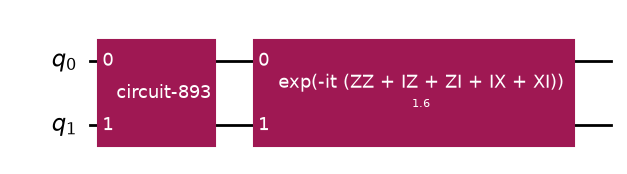

In [35]:
from qiskit_algorithms import TrotterQRTE

trotter = TrotterQRTE()
result = trotter.evolve(problem)

result.evolved_state.draw("mpl")

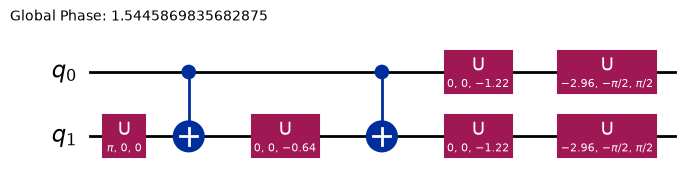

In [36]:
result.evolved_state.decompose(reps=5).decompose("disentangler_dg").decompose(
    "multiplex1_reverse_dg"
).draw("mpl")

In [37]:
statevector = Statevector(result.evolved_state)
print(statevector)
Statevector([ 0.02895926+0.08738739j, -0.9411211 +0.31187756j,
              0.00811432-0.002689j  ,  0.02895926+0.08738739j],
            dims=(2, 2))

Statevector([-0.31716909-0.08034023j, -0.83063848+0.15836263j,
              0.11859693-0.15620393j,  0.37307094+0.01622882j],
            dims=(2, 2))
Statevector([ 0.02895926+0.08738739j, -0.9411211 +0.31187756j,
              0.00811432-0.002689j  ,  0.02895926+0.08738739j],
            dims=(2, 2))


/opt/anaconda3/envs/Qiskit/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/anaconda3/envs/Qiskit/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


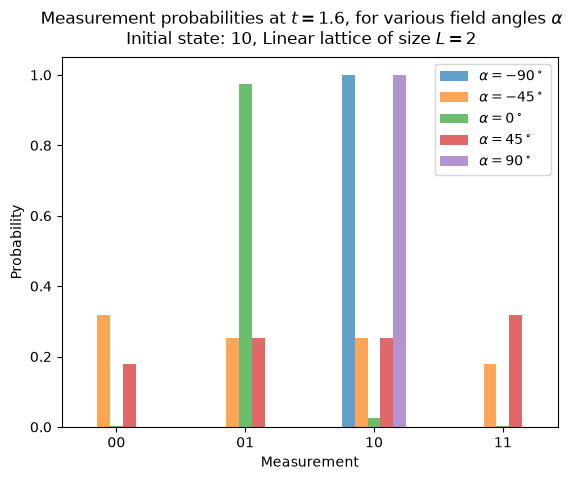

In [38]:
import numpy as np
import matplotlib.pyplot as plt

bar_width = 0.1
# We prepare an initial state ↑↓ (01).
# Note that Statevector and SparsePauliOp interpret the qubits from right to left
initial_state = Statevector.from_label("10")
trotter = TrotterQRTE()
final_time = 1.6
eps = 1e-5

# We create the list of angles in radians, with a small epsilon
# the exactly longitudinal field, which would present no dynamics at all
alphas = np.linspace(-np.pi / 2 + eps, np.pi / 2 - eps, 5)

for i, alpha in enumerate(alphas):
    H_alpha = get_hamiltonian(L=2, J=0.2, h=1.0, alpha=alpha)
    problem = TimeEvolutionProblem(H_alpha, initial_state=initial_state, time=1.6)
    result = trotter.evolve(problem)
    evolved_state = Statevector(result.evolved_state)
    # Dictionary of probabilities
    amplitudes_dict = evolved_state.probabilities_dict()
    labels = list(amplitudes_dict.keys())
    values = list(amplitudes_dict.values())
    # Convert angle to degrees
    alpha_str = f"$\\alpha={int(np.round(alpha * 180 / pi))}^\\circ$"
    plt.bar(np.arange(4) + i * bar_width, values, bar_width, label=alpha_str, alpha=0.7)

plt.xticks(np.arange(4) + 2 * bar_width, labels)
plt.xlabel("Measurement")
plt.ylabel("Probability")
plt.suptitle(
    f"Measurement probabilities at $t={final_time}$, for various field angles $\\alpha$\n"
    f"Initial state: 10, Linear lattice of size $L=2$"
)
plt.legend()
plt.show()

In [39]:
from math import pi

L = 6
H = get_hamiltonian(L=L, J=0.2, h=1.2, alpha=pi / 8)

In [40]:
from qiskit_algorithms import TrotterQRTE
from qiskit.primitives import StatevectorEstimator

num_timesteps = 60
trotter = TrotterQRTE(num_timesteps=num_timesteps, estimator=StatevectorEstimator())

In [41]:
magnetization_op = SparsePauliOp.from_sparse_list(
    [("Z", [i], 1.0) for i in range(0, L)], num_qubits=L
)
correlation_op = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], 1.0) for i in range(0, L - 1)], num_qubits=L
) / (L - 1)

In [42]:
final_time = 30.0
initial_state = Statevector.from_label("001100")
problem = TimeEvolutionProblem(
    H,
    initial_state=initial_state,
    time=final_time,
    aux_operators=[H, magnetization_op, correlation_op],
)


In [43]:
result = trotter.evolve(problem)

/opt/anaconda3/envs/Qiskit/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/anaconda3/envs/Qiskit/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


In [44]:
import numpy as np

observables = np.array(np.array(result.observables)[:, :, 0])
observables.shape

(61, 3)

Text(0.5, 0.98, 'Observable evolution')

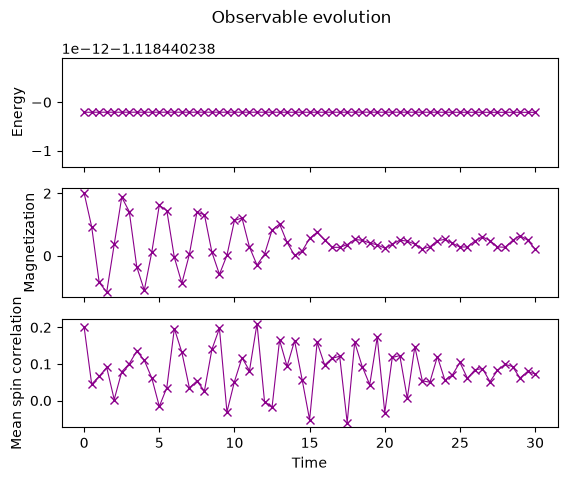

In [45]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, sharex=True)
times = np.linspace(0, final_time, num_timesteps + 1)  # includes initial state
axes[0].plot(
    times, observables[:, 0], label="First order", marker="x", c="darkmagenta", ls="-", lw=0.8
)
axes[1].plot(
    times, observables[:, 1], label="First order", marker="x", c="darkmagenta", ls="-", lw=0.8
)
axes[2].plot(
    times, observables[:, 2], label="First order", marker="x", c="darkmagenta", ls="-", lw=0.8
)
axes[0].set_ylabel("Energy")
axes[1].set_ylabel("Magnetization")
axes[2].set_ylabel("Mean spin correlation")
axes[2].set_xlabel("Time")
fig.suptitle("Observable evolution")


In [46]:
import scipy as sc

H_array = H.to_matrix()

# We define a slightly denser time mesh
exact_times = np.linspace(0, final_time, 101)

# We compute the exact evolution using the exp
exact_evolution = [
    initial_state.evolve(sc.linalg.expm(-1j * time * H_array)) for time in exact_times
]

In [47]:
exact_energy = np.real([sv.expectation_value(H) for sv in exact_evolution])
exact_magnetization = np.real([sv.expectation_value(magnetization_op) for sv in exact_evolution])
exact_correlation = np.real([sv.expectation_value(correlation_op) for sv in exact_evolution])

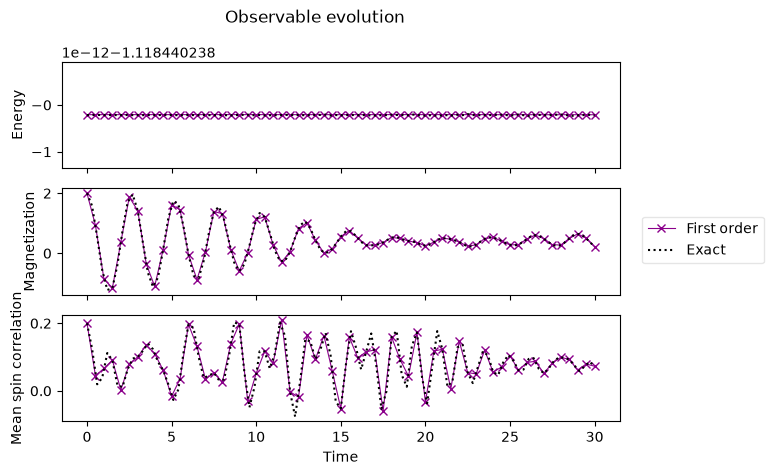

In [48]:
axes[0].plot(exact_times, exact_energy, c="k", ls=":", label="Exact")
axes[1].plot(exact_times, exact_magnetization, c="k", ls=":", label="Exact")
axes[2].plot(exact_times, exact_correlation, c="k", ls=":", label="Exact")
# Select the labels of only the first axis
legend = fig.legend(
    *axes[0].get_legend_handles_labels(),
    bbox_to_anchor=(1.0, 0.5),
    loc="center left",
    framealpha=0.5,
)
fig.tight_layout()
fig

In [4]:
def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    """Transverse-field Ising Hamiltonian on an open chain as a SparsePauliOp."""
    terms = []

    # Interaction terms: -J * Z_i Z_{i+1}
    for i in range(num_qubits - 1):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        pauli[i + 1] = "Z"
        # Qiskit reads Pauli strings right-to-left (qubit 0 is the rightmost char)
        terms.append(("".join(reversed(pauli)), -J))

    # Field terms: -h * X_i
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), -h))

    return SparsePauliOp.from_list(terms)


num_qubits = 4
J, h = 1.0, 1.0
H = tfim_hamiltonian(num_qubits, J, h)

print(f"TFIM on {num_qubits} qubits (J={J}, h={h}):")
print(H)

TFIM on 4 qubits (J=1.0, h=1.0):
SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'IIIX', 'IIXI', 'IXII', 'XIII'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j])


One Trotter step (dt=0.2):  depth = 10, 2-qubit gates = 6


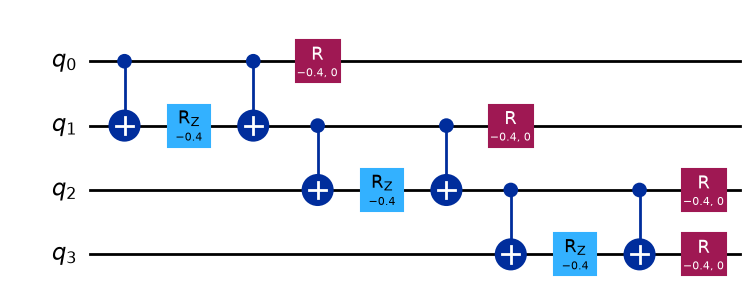

In [5]:
# A single Trotter step for a small time dt, using the first-order Lie-Trotter formula.
dt = 0.2
single_step = PauliEvolutionGate(H, time=dt, synthesis=LieTrotter(reps=1))

demo = QuantumCircuit(num_qubits)
demo.append(single_step, range(num_qubits))
demo = demo.decompose(reps=2)  # unroll into elementary gates so we can see them

print(f"One Trotter step (dt={dt}):  depth = {demo.depth()}, "
      f"2-qubit gates = {demo.num_nonlocal_gates()}")
demo.draw("mpl", fold=-1)

Circuit for t = 1.0


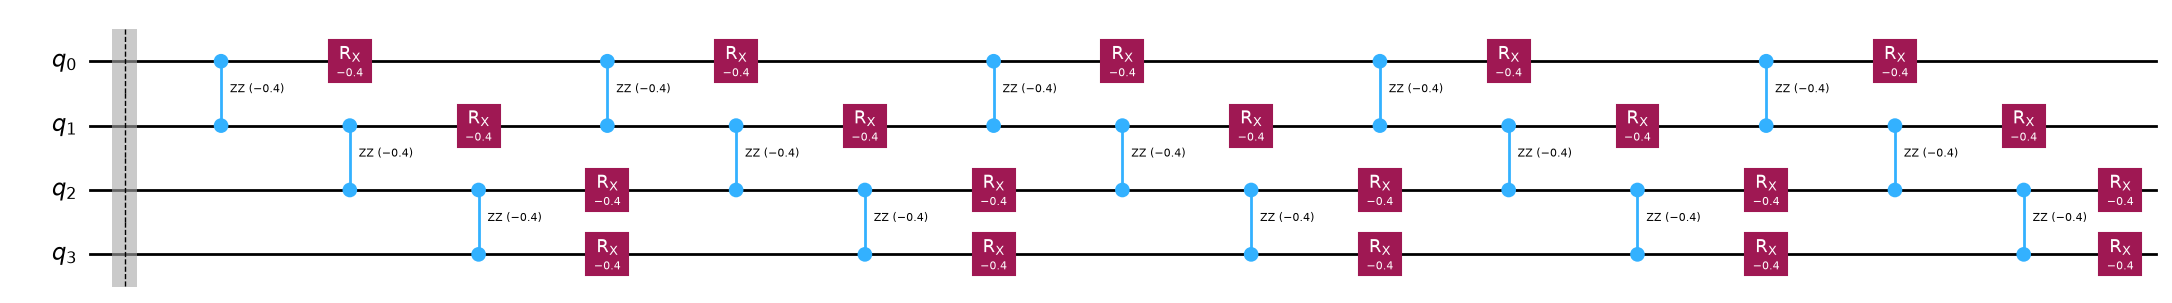

In [6]:
def trotter_evolution_circuit(H, num_qubits, dt, n_steps, order=1):
    """Prepare |00..0> and apply n_steps Trotter steps of size dt."""
    if order == 1:
        synth = LieTrotter(reps=1)
    else:
        synth = SuzukiTrotter(order=order, reps=1)

    qc = QuantumCircuit(num_qubits)
    # initial state |00..0> is the default; add an explicit barrier for clarity
    qc.barrier()

    step = PauliEvolutionGate(H, time=dt, synthesis=synth)
    for _ in range(n_steps):
        qc.append(step, range(num_qubits))

    return qc.decompose() # change to qc if needed --------------------------


# Example: 5 steps of size dt reaches time t = 5*dt
example = trotter_evolution_circuit(H, num_qubits, dt=0.2, n_steps=5)
print("Circuit for t =", 5 * 0.2)
example.draw("mpl", fold=-1)

In [7]:
def magnetization_op(num_qubits):
    """(1/N) * sum_i Z_i as a SparsePauliOp."""
    terms = []
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        terms.append(("".join(reversed(pauli)), 1.0 / num_qubits))
    return SparsePauliOp.from_list(terms)


Mz = magnetization_op(num_qubits)
estimator = StatevectorEstimator()

# --- Trotterized evolution ---
dt = 0.15
max_steps = 10
times = np.array([n * dt for n in range(max_steps + 1)])

mz_trotter = []
for n in range(max_steps + 1):
    circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=n)
    result = estimator.run([(circ, Mz)]).result()
    mz_trotter.append(float(result[0].data.evs))
mz_trotter = np.array(mz_trotter)

In [8]:
# --- Exact reference evolution (classical, small systems only) ---
from scipy.linalg import expm

H_matrix = H.to_matrix()
Mz_matrix = Mz.to_matrix()
psi0 = Statevector.from_label("0" * num_qubits).data

mz_exact = []
for t in times:
    U = expm(-1j * H_matrix * t)
    psi_t = U @ psi0
    val = np.real(np.conj(psi_t) @ Mz_matrix @ psi_t)
    mz_exact.append(val)
mz_exact = np.array(mz_exact)

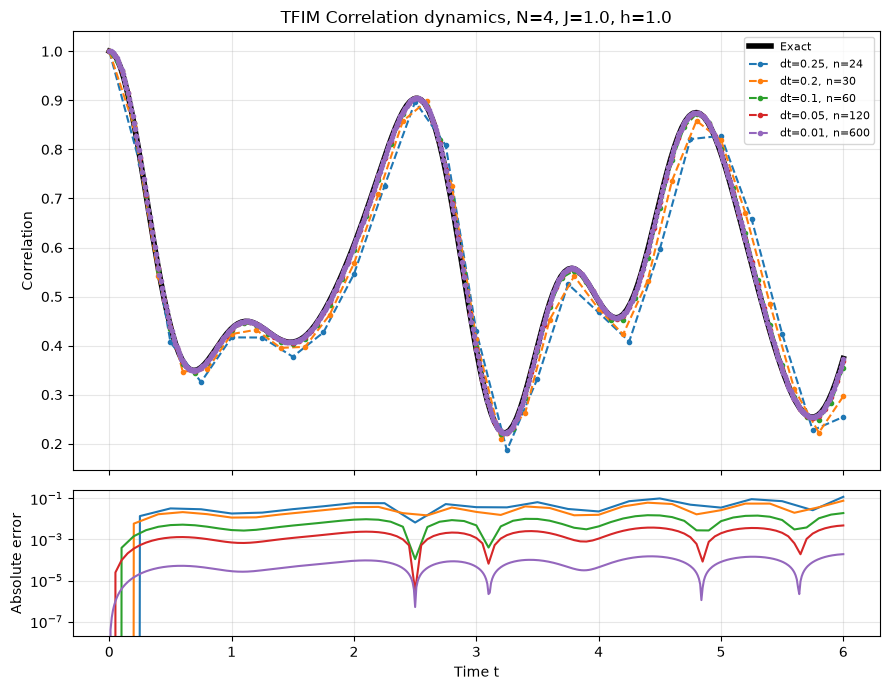

In [12]:
## T = 6, 1st Order Lie-Trotter for Correlation

T = 6 
dt_vals = [0.25, 0.2, 0.1, 0.05, 0.01]

Czz = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], 1 / (num_qubits - 1))
     for i in range(num_qubits - 1)],
    num_qubits=num_qubits
)

Czz_matrix = Czz.to_matrix()

def exact_correlation(t):
    psi_t = expm(-1j * H_matrix * t) @ psi0
    return float(np.real(np.vdot(psi_t, Czz_matrix @ psi_t)))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, 
    gridspec_kw={"height_ratios": [3,1]}
)

exact_times = np.linspace(0, T, 201)
ax1.plot(exact_times, [exact_correlation(t) for t in exact_times], "k-", lw=4, label="Exact")

results = {}

for dt in dt_vals:
    n_steps = int(round(T/dt))

    times = np.arange(n_steps + 1) * dt
    corr_trotter = []

    for k in range(n_steps + 1):
        circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=k, order=1)
        result = estimator.run([(circ, Czz)]).result()
        corr_trotter.append(float(result[0].data.evs))

    corr_trotter = np.array(corr_trotter)
    corr_exact = np.array([exact_correlation(t) for t in times])

    errors = np.abs(corr_trotter - corr_exact)

    results[dt] = {
        "times": times,
        "corr_trotter": corr_trotter,
        "corr_exact": corr_exact,
        "errors": errors
    }

    line, = ax1.plot(
        times, corr_trotter, "o--", ms=3, label=f"dt={dt:g}, n={n_steps}"
    )

    ax2.plot(times, errors, color=line.get_color())

ax1.set_ylabel(r"Correlation")
ax1.set_title(f"TFIM Correlation dynamics, N={num_qubits}, J={J}, h={h}")
ax1.legend(fontsize=8)

ax2.set_xlabel("Time t")
ax2.set_ylabel("Absolute error")
ax2.set_yscale("log")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

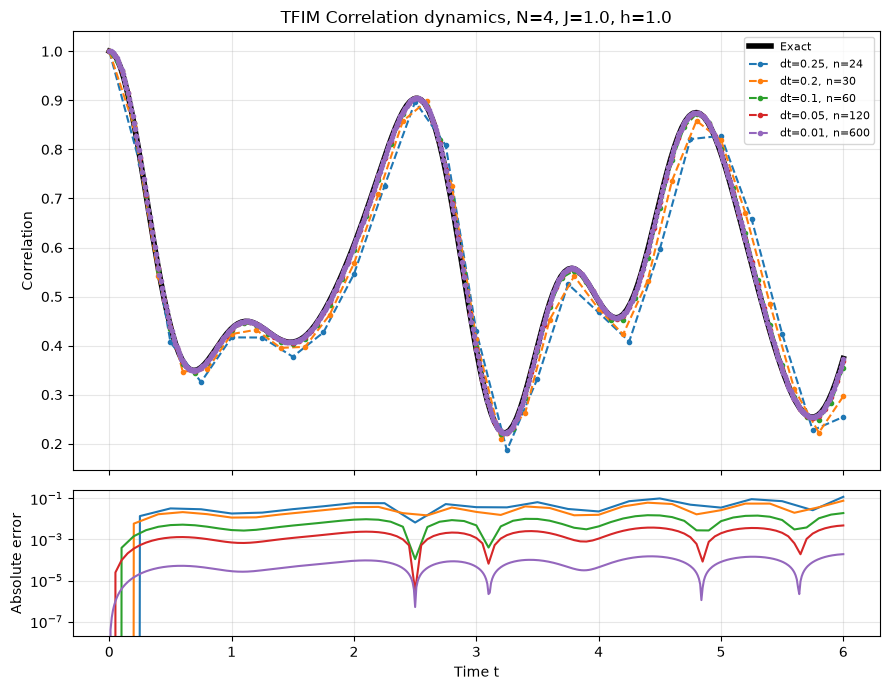

In [13]:
## T = 6, 2nd Order Suzuki-Trotter for Correlation

T = 6 
dt_vals = [0.25, 0.2, 0.1, 0.05, 0.01]

Czz = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], 1 / (num_qubits - 1))
     for i in range(num_qubits - 1)],
    num_qubits=num_qubits
)

Czz_matrix = Czz.to_matrix()

def exact_correlation(t):
    psi_t = expm(-1j * H_matrix * t) @ psi0
    return float(np.real(np.vdot(psi_t, Czz_matrix @ psi_t)))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, 
    gridspec_kw={"height_ratios": [3,1]}
)

exact_times = np.linspace(0, T, 201)
ax1.plot(exact_times, [exact_correlation(t) for t in exact_times], "k-", lw=4, label="Exact")

results = {}

for dt in dt_vals:
    n_steps = int(round(T/dt))

    times = np.arange(n_steps + 1) * dt
    corr_trotter = []

    for k in range(n_steps + 1):
        circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=k, order=2)
        result = estimator.run([(circ, Czz)]).result()
        corr_trotter.append(float(result[0].data.evs))

    corr_trotter = np.array(corr_trotter)
    corr_exact = np.array([exact_correlation(t) for t in times])

    errors = np.abs(corr_trotter - corr_exact)

    results[dt] = {
        "times": times,
        "corr_trotter": corr_trotter,
        "corr_exact": corr_exact,
        "errors": errors
    }

    line, = ax1.plot(
        times, corr_trotter, "o--", ms=3, label=f"dt={dt:g}, n={n_steps}"
    )

    ax2.plot(times, errors, color=line.get_color())

ax1.set_ylabel(r"Correlation")
ax1.set_title(f"TFIM Correlation dynamics, N={num_qubits}, J={J}, h={h}")
ax1.legend(fontsize=8)

ax2.set_xlabel("Time t")
ax2.set_ylabel("Absolute error")
ax2.set_yscale("log")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

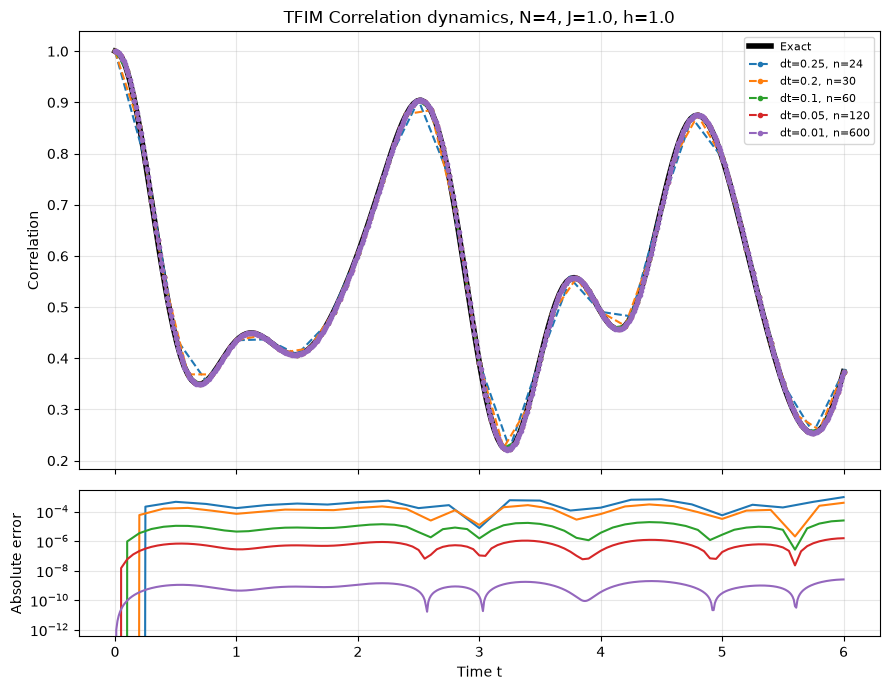

In [14]:
## T = 6, 4th Order Suzuki-Trotter for Correlation

T = 6 
dt_vals = [0.25, 0.2, 0.1, 0.05, 0.01]

Czz = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], 1 / (num_qubits - 1))
     for i in range(num_qubits - 1)],
    num_qubits=num_qubits
)

Czz_matrix = Czz.to_matrix()

def exact_correlation(t):
    psi_t = expm(-1j * H_matrix * t) @ psi0
    return float(np.real(np.vdot(psi_t, Czz_matrix @ psi_t)))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, 
    gridspec_kw={"height_ratios": [3,1]}
)

exact_times = np.linspace(0, T, 201)
ax1.plot(exact_times, [exact_correlation(t) for t in exact_times], "k-", lw=4, label="Exact")

results = {}

for dt in dt_vals:
    n_steps = int(round(T/dt))

    times = np.arange(n_steps + 1) * dt
    corr_trotter = []

    for k in range(n_steps + 1):
        circ = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=k, order=4)
        result = estimator.run([(circ, Czz)]).result()
        corr_trotter.append(float(result[0].data.evs))

    corr_trotter = np.array(corr_trotter)
    corr_exact = np.array([exact_correlation(t) for t in times])

    errors = np.abs(corr_trotter - corr_exact)

    results[dt] = {
        "times": times,
        "corr_trotter": corr_trotter,
        "corr_exact": corr_exact,
        "errors": errors
    }

    line, = ax1.plot(
        times, corr_trotter, "o--", ms=3, label=f"dt={dt:g}, n={n_steps}"
    )

    ax2.plot(times, errors, color=line.get_color())

ax1.set_ylabel(r"Correlation")
ax1.set_title(f"TFIM Correlation dynamics, N={num_qubits}, J={J}, h={h}")
ax1.legend(fontsize=8)

ax2.set_xlabel("Time t")
ax2.set_ylabel("Absolute error")
ax2.set_yscale("log")

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()